# Minimal MNIST Flow Matching + Memorization Tracking

Smoke-test notebook: train a small UNet via flow matching on N MNIST images,
snapshot every k steps, and compute f_mem at each snapshot to watch the
memorization curve emerge.

In [23]:
import sys, os
from contextlib import nullcontext
import time

sys.path.insert(0, os.path.abspath(".."))

import torch
import numpy as np
import matplotlib.pyplot as plt
from torchvision import datasets, transforms

from experiments.natural_images.common.utils import seed_everything
from experiments.natural_images.common.flow_matching import FlowMatching
from experiments.natural_images.common.networks.unet import SmallUNet
from experiments.natural_images.common.training.ema import EMA
from experiments.natural_images.common.evaluation.memorization import (
    compute_nn_stats,
    compute_f_mem,
)

%matplotlib inline

In [ ]:
# ---- Knobs ----
FAST_NOTEBOOK = True  # flip to False for the slower, higher-fidelity notebook run
N = 4  # training set size (small = memorization regime)
PRED_SPACE = "eps"  # prediction parameterization: "x", "eps", or "v"
LOSS_SPACE = "eps"  # loss space
TOTAL_STEPS = 3000 if FAST_NOTEBOOK else 10000
SNAPSHOT_POINTS = 8 if FAST_NOTEBOOK else 20
SNAPSHOT_EVERY = max(1, TOTAL_STEPS // SNAPSHOT_POINTS)
N_GEN = 32 if FAST_NOTEBOOK else 200
SAMPLE_STEPS = 16 if FAST_NOTEBOOK else 50
SAMPLE_METHOD = "euler" if FAST_NOTEBOOK else "heun"
FINAL_SAMPLE_STEPS = 24 if FAST_NOTEBOOK else SAMPLE_STEPS
BATCH_SIZE = N
LR = 2e-4
EMA_DECAY = 0.999  # faster EMA for short runs
SEED = 42
DEVICE = (
    "mps"
    if torch.backends.mps.is_available()
    else ("cuda" if torch.cuda.is_available() else "cpu")
)
USE_AMP = DEVICE == "cuda"
USE_TORCH_COMPILE = DEVICE == "cuda" and hasattr(torch, "compile")
AMP_DTYPE = torch.bfloat16 if USE_AMP else None

print(
    f"Device: {DEVICE} | fast={FAST_NOTEBOOK} | sampler={SAMPLE_METHOD}/{SAMPLE_STEPS} | n_gen={N_GEN}"
)

Device: mps


## 1. Load MNIST subset and freeze the training tensor

Training tensor: torch.Size([4, 1, 32, 32]), range [-1.00, 0.99]


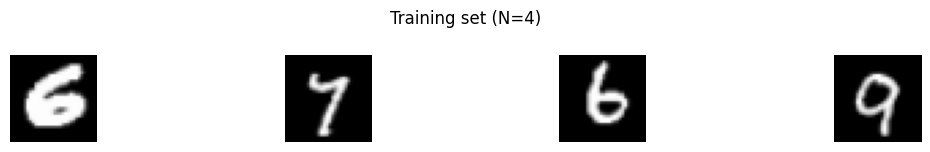

In [25]:
seed_everything(SEED)

if DEVICE == "cuda":
    # Notebook runs are smoke tests, so prefer throughput over exact determinism.
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    torch.set_float32_matmul_precision("high")

# Download MNIST, resize to 32x32, scale to [-1, 1]
tf = transforms.Compose(
    [
        transforms.Resize(32),
        transforms.ToTensor(),  # [0, 1]
        transforms.Normalize([0.5], [0.5]),  # [-1, 1]
    ]
)
full_mnist = datasets.MNIST(root="../tmp/data", train=True, download=True, transform=tf)

# Deterministic subsample of N images
perm = torch.randperm(len(full_mnist))[:N]
train_imgs = torch.stack([full_mnist[i][0] for i in perm]).contiguous()
train_imgs_device = train_imgs.to(DEVICE, non_blocking=(DEVICE == "cuda"))
if DEVICE == "cuda":
    train_imgs_device = train_imgs_device.contiguous(memory_format=torch.channels_last)

print(
    f"Training tensor: {train_imgs.shape}, range [{train_imgs.min():.2f}, {train_imgs.max():.2f}]"
)

# Quick look at a few samples
fig, axes = plt.subplots(1, 4, figsize=(12, 1.5))
for i, ax in enumerate(axes):
    ax.imshow(train_imgs[i, 0].cpu(), cmap="gray", vmin=-1, vmax=1)
    ax.axis("off")
fig.suptitle(f"Training set (N={N})")
plt.tight_layout()

## 2. Build model: SmallUNet + FlowMatching wrapper

In [26]:
# Small UNet for 32x32 greyscale — use base_channels=32 to keep it light
network = SmallUNet(
    in_channels=1,
    base_channels=32,
    channel_mults=(1, 4),
    attention_resolutions=(8,),
    num_res_blocks=2,
    dropout=0.0,
)
flow_model = FlowMatching(network, pred_space=PRED_SPACE, loss_space=LOSS_SPACE).to(
    DEVICE
)
if DEVICE == "cuda":
    flow_model = flow_model.to(memory_format=torch.channels_last)
if USE_TORCH_COMPILE:
    flow_model.network = torch.compile(flow_model.network, mode="reduce-overhead")

n_params = sum(p.numel() for p in flow_model.parameters())
print(
    f"Model params: {n_params / 1e6:.2f}M | pred={PRED_SPACE}, loss={LOSS_SPACE} | amp={USE_AMP} | compile={USE_TORCH_COMPILE}"
)

Model params: 3.17M  |  pred=v, loss=v


## 3. Training loop with periodic snapshots

Every `SNAPSHOT_EVERY` steps: generate samples with EMA weights, compute f_mem.

In [27]:
# import tqdm  functionality
from tqdm import tqdm

In [28]:
# Optimizer and EMA
optimizer = torch.optim.AdamW(flow_model.parameters(), lr=LR, weight_decay=1e-4)
ema = EMA(flow_model, decay=EMA_DECAY)
scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

# Tracking
loss_log = []
snapshot_log = []  # list of {"step": int, "f_mem": float, "mean_r": float, "sample_seconds": float}
n_train = len(train_imgs_device)

flow_model.train()
pbar = tqdm(range(1, TOTAL_STEPS + 1), desc="Training", ncols=120)
for step in pbar:
    if BATCH_SIZE >= n_train:
        batch = train_imgs_device
    else:
        idx = torch.randint(0, n_train, (BATCH_SIZE,), device=DEVICE)
        batch = train_imgs_device.index_select(0, idx)
    if DEVICE == "cuda":
        batch = batch.contiguous(memory_format=torch.channels_last)

    optimizer.zero_grad(set_to_none=True)
    autocast_ctx = torch.autocast(device_type="cuda", dtype=AMP_DTYPE) if USE_AMP else nullcontext()
    with autocast_ctx:
        loss = flow_model.compute_loss(batch)
    if USE_AMP:
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
    else:
        loss.backward()
        optimizer.step()
    ema.update()

    loss_value = float(loss.detach())
    loss_log.append(loss_value)
    pbar.set_postfix(loss=f"{loss_value:.4f}")

    # ---- Snapshot ----
    if step % SNAPSHOT_EVERY == 0 or step == TOTAL_STEPS:
        snapshot_start = time.perf_counter()
        ema.apply()
        flow_model.eval()
        with torch.inference_mode():
            samples = flow_model.sample(
                shape=(N_GEN, 1, 32, 32),
                n_steps=SAMPLE_STEPS,
                method=SAMPLE_METHOD,
                device=DEVICE,
            ).float().cpu()
        flow_model.train()
        ema.restore()

        nn_stats = compute_nn_stats(samples, train_imgs)
        f_mem = compute_f_mem(nn_stats["r"], threshold=0.5)
        mean_r = nn_stats["r"].mean().item()
        sample_seconds = time.perf_counter() - snapshot_start

        snapshot_log.append(
            {
                "step": step,
                "f_mem": f_mem,
                "mean_r": mean_r,
                "sample_seconds": sample_seconds,
            }
        )
        pbar.set_postfix(
            loss=f"{loss_value:.4f}",
            f_mem=f"{f_mem:.3f}",
            mean_r=f"{mean_r:.3f}",
            snap_s=f"{sample_seconds:.1f}",
        )

print("Done.")

Training:   5%|█▊                                  | 498/10000 [00:17<05:24, 29.28it/s, loss=0.1075]

Sampling...


Training:   5%|█▋                                | 502/10000 [00:40<5:03:57,  1.92s/it, loss=0.0966]

Generated 200 samples


Training:  10%|███▌                                | 997/10000 [00:57<05:24, 27.73it/s, loss=0.0660]

Sampling...


... (70 outputs left out)

Training: 100%|██████████████████████████████████▉| 9998/10000 [13:59<00:00, 29.04it/s, loss=0.0045]

Sampling...


Training: 100%|███████| 10000/10000 [14:22<00:00, 11.60it/s, f_mem=1.000, loss=0.0045, mean_r=0.082]

Generated 200 samples
Done.


## 4. Results

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))

# (a) Loss curve — log scale
axes[0].semilogy(loss_log, alpha=0.3, linewidth=0.5, label="raw")
# smoothed
window = min(50, len(loss_log) // 4)
if window > 1:
    smooth = np.convolve(loss_log, np.ones(window) / window, mode="valid")
    axes[0].semilogy(range(window - 1, len(loss_log)), smooth, color="C0", linewidth=1.5, label="smoothed")
axes[0].set_xlabel("Step")
axes[0].set_ylabel("Loss (log scale)")
axes[0].set_title("Training loss")
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)

# (b) f_mem over training
steps = [s["step"] for s in snapshot_log]
fmems = [s["f_mem"] for s in snapshot_log]
axes[1].plot(steps, fmems, "o-", color="C1")
axes[1].axhline(0.5, ls="--", color="gray", alpha=0.5, label="f_mem = 0.5")
axes[1].set_xlabel("Step")
axes[1].set_ylabel("f_mem")
axes[1].set_ylim(-0.05, 1.05)
axes[1].set_title("Memorization fraction over training")
axes[1].legend()

# (c) mean r over training
mean_rs = [s["mean_r"] for s in snapshot_log]
axes[2].plot(steps, mean_rs, "s-", color="C2")
axes[2].set_xlabel("Step")
axes[2].set_ylabel("mean r = d1/d2")
axes[2].set_ylim(0, 1.05)
axes[2].set_title("Mean NN ratio over training")

fig.suptitle(f"MNIST N={N}, pred={PRED_SPACE}, loss={LOSS_SPACE}", fontsize=13)
plt.tight_layout()
plt.show()

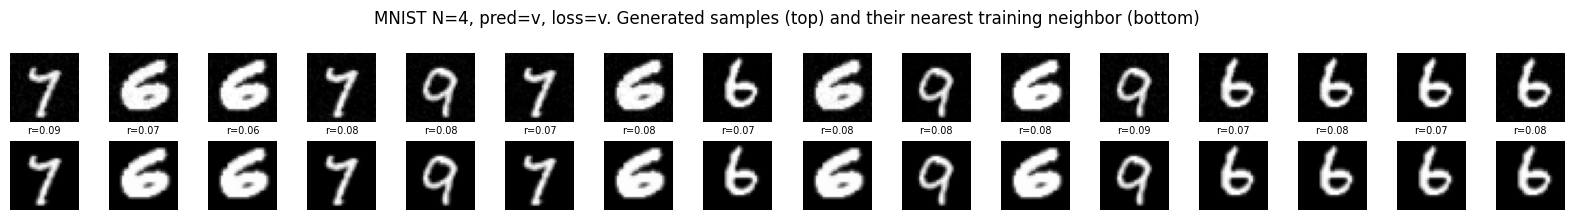

In [ ]:
# Show generated samples from the final snapshot alongside their nearest training neighbors
ema.apply()
flow_model.eval()
with torch.inference_mode():
    final_samples = flow_model.sample(
        shape=(16, 1, 32, 32),
        n_steps=FINAL_SAMPLE_STEPS,
        method=SAMPLE_METHOD,
        device=DEVICE,
    ).float().cpu()
ema.restore()

final_nn = compute_nn_stats(final_samples, train_imgs)

fig, axes = plt.subplots(2, 16, figsize=(16, 2.2))
for i in range(16):
    axes[0, i].imshow(final_samples[i, 0], cmap="gray", vmin=-1, vmax=1)
    axes[0, i].axis("off")
    nn_idx = final_nn["nn_idx"][i].item()
    axes[1, i].imshow(train_imgs[nn_idx, 0], cmap="gray", vmin=-1, vmax=1)
    axes[1, i].axis("off")
    axes[1, i].set_title(f"r={final_nn['r'][i]:.2f}", fontsize=7)

axes[0, 0].set_ylabel("Gen", fontsize=9)
axes[1, 0].set_ylabel("NN", fontsize=9)
fig.suptitle(
    f"MNIST N={N}, pred={PRED_SPACE}, loss={LOSS_SPACE}. Generated samples (top) and their nearest training neighbor (bottom)"
)
plt.tight_layout()
plt.show()

In [39]:
# Summary table
import pandas as pd

df = pd.DataFrame(snapshot_log)
df

,step,f_mem,mean_r
0,500,0.000,0.986897
1,1000,0.000,0.922074
2,1500,0.020,0.726305
3,2000,0.745,0.449633
4,2500,0.970,0.270845
5,3000,0.995,0.188753
6,3500,0.995,0.151554
7,4000,0.995,0.127741
8,4500,1.000,0.120109
9,5000,1.000,0.104745
